Memory Coalescing & Access Patterns

In [101]:
#Implèmenter  deux matrice  addition kernels 
from numba import cuda
import numpy as np
import time

@cuda.jit
def matrix_add_coalesced(a, b, out):
    x, y = cuda.grid(2)
    if y < a.shape[0] and x < a.shape[1]:
        out[y, x] = a[y, x] + b[y, x]

@cuda.jit
def matrix_add_uncoalesced(a, b, out):
    x, y = cuda.grid(2)
    if x < a.shape[0] and y < a.shape[1]:
        out[x, y] = a[x, y] + b[x, y]

print("Q1 : deux kernels CUDA définis avec succès.")
print("GPU CUDA disponible :", cuda.is_available())

Q1 : deux kernels CUDA définis avec succès.
GPU CUDA disponible : True


In [102]:
if not cuda.is_available():
    raise RuntimeError(
        "Aucun GPU NVIDIA CUDA utilisable. Vérifie le pilote NVIDIA "
        "et que le noyau VS Code utilise le bon environnement Python."
    )

N = 8192
A = np.ones((N, N), dtype=np.float32)
B = np.full((N, N), 2.0, dtype=np.float32)

# Transfert CPU (host) -> GPU (device)
d_a = cuda.to_device(A)
d_b = cuda.to_device(B)
d_out = cuda.device_array((N, N), dtype=np.float32)

print(f"Q2 : A et B = {N} x {N}, dtype = {A.dtype}")
print(f"Taille de A : {A.nbytes / (1024**2):.0f} Mio")
print(f"Taille de B : {B.nbytes / (1024**2):.0f} Mio")
print(f"Mémoire GPU minimale pour A, B et sortie : {3 * A.nbytes / (1024**2):.0f} Mio")
print("Transfert vers le GPU terminé.")

Q2 : A et B = 8192 x 8192, dtype = float32
Taille de A : 256 Mio
Taille de B : 256 Mio
Mémoire GPU minimale pour A, B et sortie : 768 Mio
Transfert vers le GPU terminé.


In [103]:
threadsperblock = (32, 8)
blockspergrid = (
    (N + threadsperblock[0] - 1) // threadsperblock[0],
    (N + threadsperblock[1] - 1) // threadsperblock[1]
)

print("Q3 : dimensions du bloc :", threadsperblock)
print("Threads par bloc :", threadsperblock[0] * threadsperblock[1])
print("Dimensions de la grille :", blockspergrid)
print("Nombre total de blocs :", blockspergrid[0] * blockspergrid[1])

Q3 : dimensions du bloc : (32, 8)
Threads par bloc : 256
Dimensions de la grille : (256, 1024)
Nombre total de blocs : 262144


In [104]:
def benchmark_kernel(kernel, iterations=10):
    # Dry run : compilation JIT et première exécution, NON chronométrées
    kernel[blockspergrid, threadsperblock](d_a, d_b, d_out)
    cuda.synchronize()

    times = []
    for _ in range(iterations):
        start = time.perf_counter()
        kernel[blockspergrid, threadsperblock](d_a, d_b, d_out)
        cuda.synchronize()  # attendre que le kernel se termine réellement
        end = time.perf_counter()
        times.append(end - start)

    return sum(times) / len(times)  # moyenne en secondes


N_ITER = 10
time_coalesced = benchmark_kernel(matrix_add_coalesced, N_ITER)
time_uncoalesced = benchmark_kernel(matrix_add_uncoalesced, N_ITER)

print(f"Q4 : temps moyen coalesced   = {time_coalesced * 1000:.4f} ms")
print(f"Q4 : temps moyen uncoalesced = {time_uncoalesced * 1000:.4f} ms")
print(f"Nombre d'itérations mesurées par kernel : {N_ITER}")

Q4 : temps moyen coalesced   = 3.5515 ms
Q4 : temps moyen uncoalesced = 6.0403 ms
Nombre d'itérations mesurées par kernel : 10


In [105]:
speedup = time_uncoalesced / time_coalesced

print(f"Q5 : speedup mesuré = {speedup:.3f}x")
if speedup > 1:
    print(f"Le kernel coalesced est environ {speedup:.2f} fois plus rapide.")
elif speedup < 1:
    print("Sur cette mesure, le kernel coalesced n'est pas plus rapide.")
else:
    print("Les deux kernels ont le même temps moyen mesuré.")

Q5 : speedup mesuré = 1.701x
Le kernel coalesced est environ 1.70 fois plus rapide.


In [106]:
bytes_transferred = 3 * (N ** 2) * 4
bandwidth_coalesced = bytes_transferred / (time_coalesced * 1e9)
bandwidth_uncoalesced = bytes_transferred / (time_uncoalesced * 1e9)

print(f"Q6 : volume de données théorique = {bytes_transferred:,} octets")
print(f"Bande passante coalesced   = {bandwidth_coalesced:.3f} GB/s")
print(f"Bande passante uncoalesced = {bandwidth_uncoalesced:.3f} GB/s")

Q6 : volume de données théorique = 805,306,368 octets
Bande passante coalesced   = 226.752 GB/s
Bande passante uncoalesced = 133.322 GB/s


Why does accessing consecutive rows instead of columns slash throughput on the same GPU hardware? NumPy stocke les matrices en row-major. Dans matrix_add_coalesced, les threads voisins accèdent à des éléments contigus (a[y, x]), ce qui permet le memory coalescing et améliore le débit mémoire. Dans matrix_add_uncoalesced, les accès (a[x, y]) sont espacés en mémoire, ce qui génère plus de transactions et réduit généralement les performances. accès contigus = coalescing = plus rapide ; accès dispersés = moins efficace.

Shared Memory Banks & Bank Conflicts

In [107]:
from numba import cuda
import numpy as np
import time

@cuda.jit
def shared_bank_stride_test(d_out, stride):
    s = cuda.shared.array(1024, dtype=np.float32)
    tid = cuda.threadIdx.x

    # Initialize shared memory
    s[tid] = tid * 1.0
    cuda.syncthreads()

    # Strided read
    val = s[(tid * stride) % 1024]
    for i in range(1000):
        val += s[(tid * stride) % 1024]

    if tid == 0:
        d_out[0] = val

print("Q1 : kernel défini (il s'exécutera sur GPU à la question 2).")

Q1 : kernel défini (il s'exécutera sur GPU à la question 2).


In [108]:
if not cuda.is_available():
    raise RuntimeError("CUDA indisponible : vérifiez votre GPU NVIDIA, le pilote et le kernel Python de VS Code.")

threads_per_block = 32
blocks_per_grid = 1

d_out = cuda.device_array(1, dtype=np.float32)

# Un premier lancement avec stride = 1
shared_bank_stride_test[blocks_per_grid, threads_per_block](d_out, 1)
cuda.synchronize()

print("Q2 : blocs =", blocks_per_grid)
print("Q2 : threads/bloc =", threads_per_block)
print("Q2 : résultat du thread 0 =", d_out.copy_to_host()[0])

Q2 : blocs = 1
Q2 : threads/bloc = 32
Q2 : résultat du thread 0 = 0.0


c:\Users\GiGi\Desktop\TPAML\.venv\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


In [109]:
strides = [1, 2, 4, 8, 16, 32]
iterations = 20
execution_times_ms = {}

for stride in strides:
    # Dry run : compilation / échauffement (hors mesures)
    shared_bank_stride_test[blocks_per_grid, threads_per_block](d_out, stride)
    cuda.synchronize()

    durations_ms = []
    for _ in range(iterations):
        cuda.synchronize()
        start = time.perf_counter()
        shared_bank_stride_test[blocks_per_grid, threads_per_block](d_out, stride)
        cuda.synchronize()
        durations_ms.append((time.perf_counter() - start) * 1000)

    execution_times_ms[stride] = sum(durations_ms) / len(durations_ms)
    print(f"stride = {stride:2d} | temps moyen = {execution_times_ms[stride]:.4f} ms")

print("Q3 : mesures terminées pour", len(strides), "strides.")

stride =  1 | temps moyen = 0.0428 ms
stride =  2 | temps moyen = 0.0512 ms
stride =  4 | temps moyen = 0.0558 ms
stride =  8 | temps moyen = 0.0350 ms
stride = 16 | temps moyen = 0.0289 ms
stride = 32 | temps moyen = 0.0295 ms
Q3 : mesures terminées pour 6 strides.


In [110]:
print("Q4 : évolution du temps en fonction du stride")
print("stride | temps moyen (ms) | conflits théoriques (voies)")
print("-" * 57)
for stride in strides:
    print(f"{stride:>6} | {execution_times_ms[stride]:>16.4f} | {min(stride, 32):>26}")

print("\nConclusion attendue en théorie : plus de conflits bancaires = plus de sérialisation.")
print("Attention : le temps mesuré peut ne pas suivre cet ordre avec le code de l'énoncé.")

Q4 : évolution du temps en fonction du stride
stride | temps moyen (ms) | conflits théoriques (voies)
---------------------------------------------------------
     1 |           0.0428 |                          1
     2 |           0.0512 |                          2
     4 |           0.0558 |                          4
     8 |           0.0350 |                          8
    16 |           0.0289 |                         16
    32 |           0.0295 |                         32

Conclusion attendue en théorie : plus de conflits bancaires = plus de sérialisation.
Attention : le temps mesuré peut ne pas suivre cet ordre avec le code de l'énoncé.


In [111]:
print("Q5 : visualisation des banques pour stride 1 et stride 32")
for stride in [1, 32]:
    indices = [(tid * stride) % 1024 for tid in range(32)]
    banks = [index % 32 for index in indices]
    print(f"\nstride = {stride}")
    print("Indices (32 threads) :", indices)
    print("Banques              :", banks)
    print("Nombre de banques utilisées :", len(set(banks)))

Q5 : visualisation des banques pour stride 1 et stride 32

stride = 1
Indices (32 threads) : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31]
Banques              : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31]
Nombre de banques utilisées : 32

stride = 32
Indices (32 threads) : [0, 32, 64, 96, 128, 160, 192, 224, 256, 288, 320, 352, 384, 416, 448, 480, 512, 544, 576, 608, 640, 672, 704, 736, 768, 800, 832, 864, 896, 928, 960, 992]
Banques              : [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Nombre de banques utilisées : 1


In [112]:
@cuda.jit
def shared_bank_stride_test_validated(d_out32, stride):
    s = cuda.shared.array(1024, dtype=np.float32)
    tid = cuda.threadIdx.x

    # Chaque thread initialise 32 éléments : 32 * 32 = 1024
    for j in range(32):
        index = tid + 32 * j
        s[index] = index * 1.0
    cuda.syncthreads()

    val = np.float32(0.0)
    for i in range(1000):
        # Une autre adresse toutes les itérations,
        # mais le numéro de banque ne change pas pour le thread.
        index = (tid * stride + 32 * i) % 1024
        val += s[index]

    # Rend observable le travail des 32 threads.
    d_out32[tid] = val

# Mesure complémentaire ; la version officielle est au-dessus.
d_out32 = cuda.device_array(32, dtype=np.float32)
print("Bonus : version alternative définie (32 sorties).")
for stride in [1, 2, 4, 8, 16, 32]:
    shared_bank_stride_test_validated[1, 32](d_out32, stride)
    cuda.synchronize()
    durations_ms = []
    for _ in range(30):
        t0 = time.perf_counter()
        shared_bank_stride_test_validated[1, 32](d_out32, stride)
        cuda.synchronize()
        durations_ms.append((time.perf_counter() - t0) * 1000)
    print(f"Bonus stride={stride:2d} : {sum(durations_ms)/len(durations_ms):.4f} ms")

Bonus : version alternative définie (32 sorties).


c:\Users\GiGi\Desktop\TPAML\.venv\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


Bonus stride= 1 : 0.0330 ms
Bonus stride= 2 : 0.0397 ms
Bonus stride= 4 : 0.0293 ms
Bonus stride= 8 : 0.0416 ms
Bonus stride=16 : 0.0332 ms
Bonus stride=32 : 0.0536 ms


2D Gaussian Filter in Global Memory

In [113]:
import numpy as np
import matplotlib.pyplot as plt
import time
from numba import cuda

print("NumPy disponible")
print("CUDA disponible :", cuda.is_available())
if not cuda.is_available():
    print("Attention : les questions 3 et 4 nécessitent un GPU NVIDIA et CUDA.")

NumPy disponible
CUDA disponible : True


In [114]:
def generate_gaussian_kernel(radius, sigma):
    """Crée un noyau gaussien normalisé de taille (2*radius+1)^2."""
    if radius < 0 or sigma <= 0:
        raise ValueError("radius >= 0 et sigma > 0 sont obligatoires")

    coords = np.arange(-radius, radius + 1, dtype=np.float32)
    yy, xx = np.meshgrid(coords, coords, indexing="ij")
    weights = (1.0 / (2.0 * np.pi * sigma**2)) * np.exp(
        -(xx**2 + yy**2) / (2.0 * sigma**2)
    )
    weights = weights / np.sum(weights)
    return weights.astype(np.float32)

RADIUS = 2
SIGMA = 1.0
kernel_from_formula = generate_gaussian_kernel(RADIUS, SIGMA)

# Matrice standard 5x5 fournie dans l'énoncé (somme des entiers = 256)
gaussian_kernel = np.array([
    [1,  4,  6,  4, 1],
    [4, 16, 24, 16, 4],
    [6, 24, 36, 24, 6],
    [4, 16, 24, 16, 4],
    [1,  4,  6,  4, 1]
], dtype=np.float32) / 256.0

# Utiliser le noyau standard pour les questions suivantes (même filtre partout).
print("Noyau gaussien calculé à partir de la formule :")
print(kernel_from_formula)
print("Somme :", kernel_from_formula.sum())
print("\nNoyau standard 5x5 du TP :")
print(gaussian_kernel)
print("Somme :", gaussian_kernel.sum())
assert gaussian_kernel.shape == (5, 5)
assert np.isclose(gaussian_kernel.sum(), 1.0)

Noyau gaussien calculé à partir de la formule :
[[0.00296902 0.01330621 0.02193823 0.01330621 0.00296902]
 [0.01330621 0.05963429 0.09832034 0.05963429 0.01330621]
 [0.02193823 0.09832034 0.16210282 0.09832034 0.02193823]
 [0.01330621 0.05963429 0.09832034 0.05963429 0.01330621]
 [0.00296902 0.01330621 0.02193823 0.01330621 0.00296902]]
Somme : 1.0

Noyau standard 5x5 du TP :
[[0.00390625 0.015625   0.0234375  0.015625   0.00390625]
 [0.015625   0.0625     0.09375    0.0625     0.015625  ]
 [0.0234375  0.09375    0.140625   0.09375    0.0234375 ]
 [0.015625   0.0625     0.09375    0.0625     0.015625  ]
 [0.00390625 0.015625   0.0234375  0.015625   0.00390625]]
Somme : 1.0


In [115]:
@cuda.jit
def gaussian_blur_global(d_in, d_out, d_kernel, width, height, radius):
    x, y = cuda.grid(2)

    if x < width and y < height:
        total = 0.0
        for dy in range(-radius, radius + 1):
            src_y = y + dy
            if src_y < 0:
                src_y = 0
            elif src_y >= height:
                src_y = height - 1

            for dx in range(-radius, radius + 1):
                src_x = x + dx
                if src_x < 0:
                    src_x = 0
                elif src_x >= width:
                    src_x = width - 1

                pixel = d_in[src_y, src_x]
                weight = d_kernel[dy + radius, dx + radius]
                total += pixel * weight

        d_out[y, x] = total

print("Kernel gaussian_blur_global défini avec succès.")

Kernel gaussian_blur_global défini avec succès.


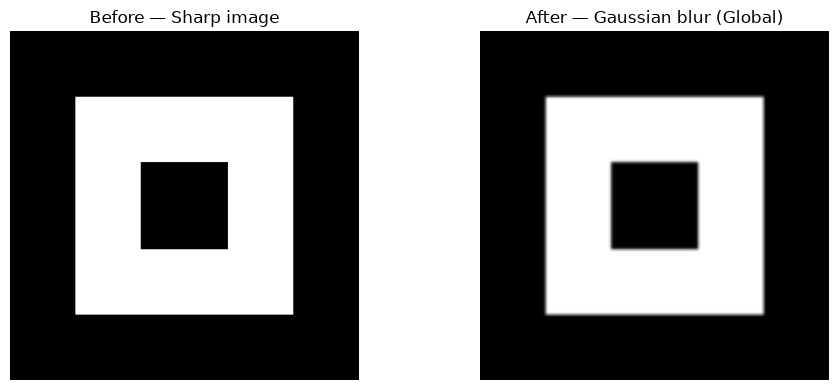

Taille image : (256, 256)
Grid : (16, 16) | Block : (16, 16)
Image modifiée : True


In [116]:
if not cuda.is_available():
    raise RuntimeError("CUDA indisponible : vérifie le GPU NVIDIA et le pilote CUDA.")

# Image nette en niveaux de gris, 256 x 256
sharp_image = np.zeros((256, 256), dtype=np.float32)
sharp_image[48:208, 48:208] = 1.0       # carré blanc
sharp_image[96:160, 96:160] = 0.0      # carré noir au centre

height, width = sharp_image.shape
block = (16, 16)
grid = ((width + block[0] - 1) // block[0],
        (height + block[1] - 1) // block[1])

d_in = cuda.to_device(sharp_image)
d_out = cuda.device_array_like(sharp_image)
d_kernel = cuda.to_device(gaussian_kernel)

gaussian_blur_global[grid, block](d_in, d_out, d_kernel, width, height, RADIUS)
cuda.synchronize()
blurred_image = d_out.copy_to_host()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(sharp_image, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Before — Sharp image")
axes[1].imshow(blurred_image, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("After — Gaussian blur (Global)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

print("Taille image :", sharp_image.shape)
print("Grid :", grid, "| Block :", block)
print("Image modifiée :", not np.allclose(sharp_image, blurred_image))

In [117]:
if not cuda.is_available():
    raise RuntimeError("CUDA indisponible : benchmark impossible sans GPU NVIDIA.")

N = 2048
benchmark_image = np.zeros((N, N), dtype=np.float32)
benchmark_image[256:1792, 256:1792] = 1.0
benchmark_image[::64, :] = 0.5           # traits nets pour varier les pixels

height, width = benchmark_image.shape
block_2048 = (16, 16)
grid_2048 = ((width + 15) // 16, (height + 15) // 16)

d_in_2048 = cuda.to_device(benchmark_image)
d_out_2048 = cuda.device_array_like(benchmark_image)
d_kernel_2048 = cuda.to_device(gaussian_kernel)

# Dry run : compilation éventuelle et chauffe du kernel
gaussian_blur_global[grid_2048, block_2048](
    d_in_2048, d_out_2048, d_kernel_2048, width, height, RADIUS
)
cuda.synchronize()

iterations = 20
times_ms = []
for _ in range(iterations):
    cuda.synchronize()
    start = time.perf_counter()

    gaussian_blur_global[grid_2048, block_2048](
        d_in_2048, d_out_2048, d_kernel_2048, width, height, RADIUS
    )

    cuda.synchronize()
    elapsed_ms = (time.perf_counter() - start) * 1000.0
    times_ms.append(elapsed_ms)

average_ms = float(np.mean(times_ms))
print("Taille image :", benchmark_image.shape)
print("Block :", block_2048, "| Grid :", grid_2048)
print("Nombre d'itérations :", iterations)
print(f"Temps moyen : {average_ms:.4f} ms")
print(f"Minimum : {min(times_ms):.4f} ms | Maximum : {max(times_ms):.4f} ms")
print("Toutes les mesures en ms :", [round(t, 4) for t in times_ms])

Taille image : (2048, 2048)
Block : (16, 16) | Grid : (128, 128)
Nombre d'itérations : 20
Temps moyen : 1.4979 ms
Minimum : 1.2533 ms | Maximum : 2.0582 ms
Toutes les mesures en ms : [1.3008, 2.0582, 1.3252, 1.3125, 1.2993, 1.8693, 1.3405, 1.2904, 1.258, 1.693, 2.043, 1.6222, 1.3089, 1.9411, 1.2713, 1.2732, 1.2634, 1.9341, 1.3004, 1.2533]


In [118]:
radius = 2
reads_per_interior_pixel = (2 * radius + 1) ** 2
print("Taille du filtre :", 2 * radius + 1, "x", 2 * radius + 1)
print("Nombre de lectures logiques par pixel interne :", reads_per_interior_pixel)
print("Nombre de relectures après la première :", reads_per_interior_pixel - 1)

Taille du filtre : 5 x 5
Nombre de lectures logiques par pixel interne : 25
Nombre de relectures après la première : 24


Tiled 2D Convolution with Shared Memory & Halo

In [119]:
# Question 1 — calculs du halo (aucun GPU requis)
TILE_W = 16
TILE_H = 16
RADIUS = 2

shared_w = TILE_W + 2 * RADIUS
shared_h = TILE_H + 2 * RADIUS
active_pixels = TILE_W * TILE_H
loaded_pixels = shared_w * shared_h
halo_pixels = loaded_pixels - active_pixels
naive_reads = active_pixels * (2 * RADIUS + 1) ** 2

print('Tuile intérieure :', TILE_W, 'x', TILE_H, '=', active_pixels, 'pixels')
print('Tuile avec halo :', shared_w, 'x', shared_h, '=', loaded_pixels, 'pixels')
print('Pixels de halo :', halo_pixels)
print('Surcoût (% des pixels intérieurs) :', 100 * halo_pixels / active_pixels)
print('Lectures globales logiques, méthode directe :', naive_reads)
print('Lectures globales logiques, méthode tiled :', loaded_pixels)
print('Rapport théorique :', naive_reads / loaded_pixels, 'fois')

Tuile intérieure : 16 x 16 = 256 pixels
Tuile avec halo : 20 x 20 = 400 pixels
Pixels de halo : 144
Surcoût (% des pixels intérieurs) : 56.25
Lectures globales logiques, méthode directe : 6400
Lectures globales logiques, méthode tiled : 400
Rapport théorique : 16.0 fois


In [120]:
# Question 2 — constantes demandées par le professeur
import numpy as np
import time
from numba import cuda

TILE_W = 16
TILE_H = 16
RADIUS = 2
SHARED_W = TILE_W + 2 * RADIUS
SHARED_H = TILE_H + 2 * RADIUS

print('TILE_W, TILE_H :', TILE_W, TILE_H)
print('RADIUS :', RADIUS)
print('SHARED_W, SHARED_H :', SHARED_W, SHARED_H)
print('Taille du bloc CUDA :', (TILE_W, TILE_H))

TILE_W, TILE_H : 16 16
RADIUS : 2
SHARED_W, SHARED_H : 20 20
Taille du bloc CUDA : (16, 16)


In [121]:
# Question 3 — kernel CUDA à tuile partagée + halo
@cuda.jit(device=True)
def _clamp_index(index, limit):
    if index < 0:
        return 0
    if index >= limit:
        return limit - 1
    return index


@cuda.jit
def gaussian_blur_shared(d_in, d_out, d_kernel, width, height):
    # 20 x 20 float32 values, private to this thread block
    s_tile = cuda.shared.array((SHARED_H, SHARED_W), dtype=np.float32)

    tx = cuda.threadIdx.x
    ty = cuda.threadIdx.y
    gx = cuda.blockIdx.x * TILE_W + tx
    gy = cuda.blockIdx.y * TILE_H + ty

    # 1) Each of the 256 threads loads one interior pixel (clamped).
    ix = _clamp_index(gx, width)
    iy = _clamp_index(gy, height)
    s_tile[ty + RADIUS, tx + RADIUS] = d_in[iy, ix]

    # 2) Boundary threads load the left and right halo strips.
    if tx < RADIUS:
        xl = _clamp_index(gx - RADIUS, width)
        xr = _clamp_index(gx + TILE_W, width)
        s_tile[ty + RADIUS, tx] = d_in[iy, xl]
        s_tile[ty + RADIUS, tx + RADIUS + TILE_W] = d_in[iy, xr]

    # 3) Boundary threads load the top and bottom halo strips.
    if ty < RADIUS:
        yt = _clamp_index(gy - RADIUS, height)
        yb = _clamp_index(gy + TILE_H, height)
        s_tile[ty, tx + RADIUS] = d_in[yt, ix]
        s_tile[ty + RADIUS + TILE_H, tx + RADIUS] = d_in[yb, ix]

    # 4) Corner threads (2 x 2) load the four halo corners.
    if tx < RADIUS and ty < RADIUS:
        xl = _clamp_index(gx - RADIUS, width)
        xr = _clamp_index(gx + TILE_W, width)
        yt = _clamp_index(gy - RADIUS, height)
        yb = _clamp_index(gy + TILE_H, height)

        s_tile[ty, tx] = d_in[yt, xl]
        s_tile[ty, tx + RADIUS + TILE_W] = d_in[yt, xr]
        s_tile[ty + RADIUS + TILE_H, tx] = d_in[yb, xl]
        s_tile[ty + RADIUS + TILE_H, tx + RADIUS + TILE_W] = d_in[yb, xr]

    # 5) All 256 threads wait for the 400 shared values to be loaded.
    cuda.syncthreads()

    # 6) Compute the 5 x 5 convolution exclusively from shared memory.
    if gx < width and gy < height:
        total = 0.0
        for dy in range(-RADIUS, RADIUS + 1):
            for dx in range(-RADIUS, RADIUS + 1):
                pixel = s_tile[ty + RADIUS + dy, tx + RADIUS + dx]
                weight = d_kernel[dy + RADIUS, dx + RADIUS]
                total += pixel * weight

        # 7) Write one output pixel to global memory.
        d_out[gy, gx] = total

print('Question 3 : gaussian_blur_shared défini avec succès.')

Question 3 : gaussian_blur_shared défini avec succès.
